# Solver Comparison (NetworkX + Pathfinding + Grid)

This notebook generates a single sample at a chosen resolution using `passage.generate.generate_sample`,
then compares NetworkX, Pathfinding and internal Grid (NumPy) solvers from `passage.generate.find_path`.

It records computation time, summarizes results, and visualizes all paths on the elevation map.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

# Add src to path for imports
ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))

In [ ]:
from passage.generate import generate_sample, find_path, _resolve_obstacle_config

In [2]:
# Solvers list (moved to top for visibility)
CONFIG_PATH = ROOT / "config" / "config.yaml"
DEFAULT_COST_MODEL = "elevation"

try:
    with open(CONFIG_PATH) as f:
        _config = yaml.safe_load(f) or {}
    _solver_cfg = _config.get("solver", {})
    _obstacle_settings = _resolve_obstacle_config(_config)
    COST_MODEL = (
        _solver_cfg.get("grid", {}).get("cost_model")
        or _solver_cfg.get("networkx", {}).get("cost_model")
        or _solver_cfg.get("pathfinding", {}).get("cost_model")
        or DEFAULT_COST_MODEL
    )
    OBSTACLES_ENABLED = bool(_obstacle_settings.get("enabled", False))
    OBSTACLE_PENALTY = float(_obstacle_settings.get("obstacle_penalty", 1e8))
except Exception:
    COST_MODEL = DEFAULT_COST_MODEL
    OBSTACLES_ENABLED = False
    OBSTACLE_PENALTY = 1e8

SOLVERS = [
    # NetworkX
    {"name": "networkx:astar", "heuristic": "euclidean", "cost_model": COST_MODEL, "label": "NetworkX A* (Euclidean)"},
    {
        "name": "networkx:astar_bi",
        "heuristic": "euclidean",
        "cost_model": COST_MODEL,
        "label": "NetworkX A* (Bidirectional)",
    },
    {"name": "networkx:dijkstra", "cost_model": COST_MODEL, "label": "NetworkX Dijkstra"},
    {"name": "networkx:dijkstra_bi", "cost_model": COST_MODEL, "label": "NetworkX Dijkstra (Bidirectional)"},
    {"name": "networkx:bellman_ford", "cost_model": COST_MODEL, "label": "NetworkX Bellman-Ford"},
    {"name": "networkx:unweighted", "cost_model": COST_MODEL, "label": "NetworkX Unweighted (BFS)"},
    # Pathfinding
    {
        "name": "pathfinding:astar",
        "heuristic": "euclidean",
        "cost_model": COST_MODEL,
        "label": "Pathfinding A* (Euclidean)",
    },
    {"name": "pathfinding:dijkstra", "cost_model": COST_MODEL, "label": "Pathfinding Dijkstra"},
    {
        "name": "pathfinding:best_first",
        "heuristic": "euclidean",
        "cost_model": COST_MODEL,
        "label": "Pathfinding Best-First",
    },
    # Grid (NumPy-based internal solvers)
    {"name": "grid:astar", "heuristic": "euclidean", "cost_model": COST_MODEL, "label": "Grid A* (NumPy)"},
    {"name": "grid:dijkstra", "cost_model": COST_MODEL, "label": "Grid Dijkstra (NumPy)"},
]

## Configuration

Choose a resolution and where to store the generated sample.

In [3]:
# Sample generation settings
RESOLUTION = 128  # 64, 128, 256, 512, 1024, 2048, 4096
SAMPLE_INDEX = 0
DISABLE_IMAGES = False
OVERRIDE_EXISTING = True

# Paths
OUTPUTS_DIR = ROOT / "outputs" / "solve"
TILES_DIR = ROOT / "outputs" / "download" / "tiles"
CALIBRATE_PATH = ROOT / "outputs" / "calibrate" / "calibrate.json"
OBSTACLE_SETTINGS = _resolve_obstacle_config(_config if "_config" in globals() else {})
USE_OBSTACLES = bool(OBSTACLE_SETTINGS.get("enabled", False))
OBSTACLE_PENALTY = float(OBSTACLE_SETTINGS.get("obstacle_penalty", 1e8))

# Solver defaults for sample generation (used only to ensure a valid path exists)
GEN_SOLVER_CONFIG = {
    "name": "grid:astar",
    "diagonal_movement": "always",
    "weight": 30.0,
    "cost_model": COST_MODEL,
    "heuristic": "euclidean",
}

# Solver comparison settings
WEIGHT = 30.0
DIAGONAL_MOVEMENT = "always"
COST_MODEL = COST_MODEL  # Pathfinding supports elevation, distance, absolute_elevation

## Generate or Load Sample

This uses `generate_sample` from `passage.generate` to create a single tensor if it does not exist yet.

In [4]:
# Validate required inputs
if not CALIBRATE_PATH.exists():
    raise FileNotFoundError(f"Calibration file not found: {CALIBRATE_PATH}. Run 'passage calibrate' first.")
if not TILES_DIR.exists():
    raise FileNotFoundError(f"Tiles directory not found: {TILES_DIR}. Run 'passage download' first.")

# Load calibration data
with open(CALIBRATE_PATH) as f:
    calibration = json.load(f)
global_min = float(calibration["global_min"])
global_max = float(calibration["global_max"])
tile_stats_df = pd.DataFrame(calibration["tile_stats"])

# Generate sample if not present (or if OVERRIDE_EXISTING is True)
tensor_path = OUTPUTS_DIR / str(RESOLUTION) / "tensors" / f"{SAMPLE_INDEX:010d}.npy"
metadata_path = OUTPUTS_DIR / str(RESOLUTION) / "metadata" / f"{SAMPLE_INDEX:010d}.yaml"

if OVERRIDE_EXISTING or not tensor_path.exists() or not metadata_path.exists():
    OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
    args = (
        SAMPLE_INDEX,
        TILES_DIR,
        OUTPUTS_DIR,
        RESOLUTION,
        tile_stats_df,
        global_min,
        global_max,
        DISABLE_IMAGES,
        GEN_SOLVER_CONFIG,
        OBSTACLE_SETTINGS,
    )
    index, success, message, duration = generate_sample(args)
    print(f"Generate sample: success={success}, message='{message}', duration={duration:.2f}s")
    if not success:
        raise RuntimeError("Sample generation failed. Try a different resolution or re-run calibration.")
else:
    print(f"Using existing tensor: {tensor_path}")

# Load tensor (shape: H, W, 3) -> channels: elevation (normalized), markers, obstacles
tensor = np.load(tensor_path)
elevation_norm = tensor[:, :, 0]
markers = tensor[:, :, 1]
obstacles_mask = tensor[:, :, 2] if tensor.shape[2] > 2 else np.zeros_like(markers)
# elevation_raw is the unnormalized elevation in the original units
elevation_raw = elevation_norm * (global_max - global_min) + global_min

2026-01-16 14:58:43.741 | DEBUG    | passage.generate:wrapper:270 - ### ENTER generate_sample()
2026-01-16 14:58:43.743 | DEBUG    | passage.generate:generate_sample:1439 - Loading full grid for center=(11,-74) half_tiles=1
2026-01-16 14:58:43.744 | DEBUG    | passage.generate:wrapper:270 - ### ENTER load_tile_grid()
2026-01-16 14:58:43.744 | DEBUG    | passage.generate:wrapper:270 - ### ENTER load_tile()
2026-01-16 14:58:43.979 | DEBUG    | passage.generate:load_tile:970 - Tile not found for lat=12, lon=-75 in directory /home/t0300081/projects/PASSAGE/passage/outputs/download/tiles; returning zeros
2026-01-16 14:58:43.980 | DEBUG    | passage.generate:wrapper:277 - ### EXIT load_tile() duration=0.2355s
2026-01-16 14:58:43.980 | DEBUG    | passage.generate:wrapper:270 - ### ENTER load_tile()


2026-01-16 14:58:44.133 | DEBUG    | passage.generate:load_tile:970 - Tile not found for lat=12, lon=-74 in directory /home/t0300081/projects/PASSAGE/passage/outputs/download/tiles; returning zeros
2026-01-16 14:58:44.134 | DEBUG    | passage.generate:wrapper:277 - ### EXIT load_tile() duration=0.1532s
2026-01-16 14:58:44.135 | DEBUG    | passage.generate:wrapper:270 - ### ENTER load_tile()
2026-01-16 14:58:44.136 | DEBUG    | passage.generate:load_tile:954 - Using tile file: /home/t0300081/projects/PASSAGE/passage/outputs/download/tiles/ALPSMLC30_N012W073_DSM.tif
2026-01-16 14:58:44.355 | DEBUG    | passage.generate:wrapper:277 - ### EXIT load_tile() duration=0.2195s
2026-01-16 14:58:44.600 | DEBUG    | passage.generate:wrapper:270 - ### ENTER load_tile()
2026-01-16 14:58:44.601 | DEBUG    | passage.generate:load_tile:954 - Using tile file: /home/t0300081/projects/PASSAGE/passage/outputs/download/tiles/ALPSMLC30_N011W075_DSM.tif
2026-01-16 14:58:44.702 | DEBUG    | passage.generate:wr

Generate sample: success=True, message='Generated sample 0', duration=2.29s


## Extract Markers

Use the marker channel to recover the start/end coordinates.

In [5]:
marker_positions = np.argwhere(markers > 0.5)
if len(marker_positions) < 2:
    raise ValueError("Expected at least two markers in the tensor.")

start = tuple(marker_positions[0])
end = tuple(marker_positions[1])

print(f"Start: {start}")
print(f"End:   {end}")
print(f"Euclidean distance: {np.hypot(start[0] - end[0], start[1] - end[1]):.1f} pixels")

Start: (np.int64(20), np.int64(23))
End:   (np.int64(65), np.int64(111))
Euclidean distance: 98.8 pixels


## Visualize Elevation Map

Visualize elevation map and markers.

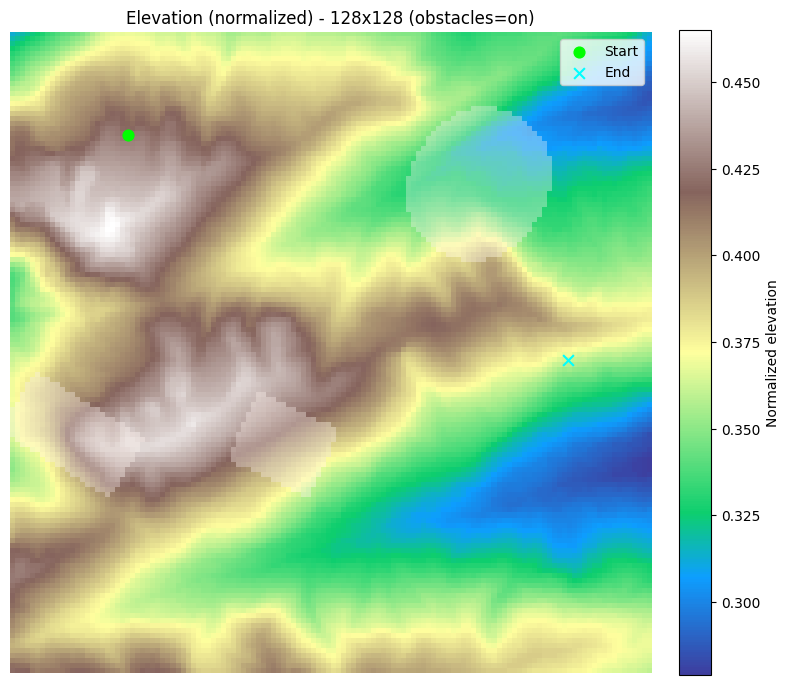

In [6]:
# Display elevation map with the same "terrain" colormap and show markers if available
fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(elevation_norm, cmap="terrain", alpha=0.95)
if USE_OBSTACLES:
    ax.imshow(np.ma.masked_where(obstacles_mask == 0, obstacles_mask), cmap="Reds", alpha=0.35)
ax.set_title(f"Elevation (normalized) - {RESOLUTION}x{RESOLUTION} (obstacles={'on' if USE_OBSTACLES else 'off'})")
ax.axis("off")
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Normalized elevation")

# Plot start/end markers if present (use existing `start`/`end` if defined, else derive from markers)
marker_positions = None
try:
    marker_positions = np.array([start, end])
except NameError:
    marker_positions = np.argwhere(markers > 0.5)

if marker_positions is not None and len(marker_positions) > 0:
    if marker_positions.shape[0] >= 1:
        s = tuple(marker_positions[0])
        ax.scatter([s[1]], [s[0]], c="lime", s=60, marker="o", label="Start", zorder=5)
    if marker_positions.shape[0] >= 2:
        e = tuple(marker_positions[1])
        ax.scatter([e[1]], [e[0]], c="cyan", s=60, marker="x", label="End", zorder=5)
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

## Run Solver Comparison

Compare all NetworkX and Pathfinding solvers and record execution time.

In [7]:
# Apply obstacles if configured
elevation_input = elevation_raw
if USE_OBSTACLES:
    elevation_input = elevation_raw.copy()
    elevation_input[obstacles_mask == 1] = elevation_input.max() + OBSTACLE_PENALTY

# Prebuild NetworkX graphs for each cost_model used by networkx solvers (reuse if multiple solvers use same model)
networkx_solvers = [s for s in SOLVERS if s["name"].split(":", 1)[0] == "networkx"]
G_prebuilt_map = {}
if networkx_solvers:
    from passage.generate import build_graph_from_elevation

    # Build a shared graph per cost_model (defaults to global COST_MODEL)
    cost_models = set(s.get("cost_model", COST_MODEL) for s in networkx_solvers)
    for cm in cost_models:
        G_prebuilt_map[cm] = build_graph_from_elevation(
            elevation_input, weight=WEIGHT, diagonal_movement=DIAGONAL_MOVEMENT, cost_model=cm
        )

results = []

for solver_info in SOLVERS:
    solver_config = {
        "name": solver_info["name"],
        "diagonal_movement": DIAGONAL_MOVEMENT,
        "weight": WEIGHT,
        "cost_model": solver_info.get("cost_model", COST_MODEL),
    }
    if "heuristic" in solver_info:
        solver_config["heuristic"] = solver_info["heuristic"]

    t0 = time.perf_counter()

    backend_name = solver_info["name"].split(":", 1)[0]
    if backend_name == "networkx":
        prebuilt = G_prebuilt_map.get(solver_config["cost_model"])
        path = find_path(elevation_input, start, end, solver_config, prebuilt_graph=prebuilt)
    else:
        path = find_path(elevation_input, start, end, solver_config)

    elapsed = (time.perf_counter() - t0) * 1000

    results.append(
        {
            "solver": solver_info["label"],
            "backend": backend_name,
            "path_length": len(path),
            "time_ms": elapsed,
            "path": path,
        }
    )

    print(f"{solver_info['label']}: path_len={len(path)}, time={elapsed:.1f} ms")


timings_df = pd.DataFrame(
    [
        {"Solver": r["solver"], "Backend": r["backend"], "Path Length": r["path_length"], "Time (ms)": r["time_ms"]}
        for r in results
    ]
)
csv_path = OUTPUTS_DIR / f"solver_times_{RESOLUTION}_{SAMPLE_INDEX:010d}.csv"
csv_path.parent.mkdir(parents=True, exist_ok=True)

timings_df.to_csv(csv_path, index=False)
print(f"Saved timings to: {csv_path}")

2026-01-16 14:58:46.202 | DEBUG    | passage.generate:wrapper:270 - ### ENTER build_graph_from_elevation()
2026-01-16 14:58:46.203 | DEBUG    | passage.generate:build_graph_from_elevation:448 - build_graph_from_elevation: start rows=128, cols=128, diagonal=always, cost_model=elevation, weight=30.0, graph_backend=edges
2026-01-16 14:58:46.416 | DEBUG    | passage.generate:build_graph_from_elevation:461 - build_graph_from_elevation: template fetch took 0.2127s
2026-01-16 14:58:46.418 | DEBUG    | passage.generate:build_graph_from_elevation:465 - build_graph_from_elevation: weights compute took 0.0015s
2026-01-16 14:58:46.561 | DEBUG    | passage.generate:build_graph_from_elevation:479 - build_graph_from_elevation: edge weights update took 0.1417s
2026-01-16 14:58:46.561 | DEBUG    | passage.generate:build_graph_from_elevation:480 - build_graph_from_elevation: total time 0.3582s
2026-01-16 14:58:46.562 | DEBUG    | passage.generate:wrapper:277 - ### EXIT build_graph_from_elevation() durat

NetworkX A* (Euclidean): path_len=89, time=17.6 ms
NetworkX A* (Bidirectional): path_len=89, time=14.8 ms
NetworkX Dijkstra: path_len=89, time=55.3 ms
NetworkX Dijkstra (Bidirectional): path_len=89, time=45.6 ms
NetworkX Bellman-Ford: path_len=89, time=83.8 ms


2026-01-16 14:58:46.780 | DEBUG    | passage.generate:find_path:590 - Using prebuilt NetworkX graph; skipping build_graph_from_elevation()
2026-01-16 14:58:46.782 | DEBUG    | passage.generate:find_path:600 - Graph construction: nodes=16384, edges=129540, time=0.0000s
2026-01-16 14:58:46.795 | DEBUG    | passage.generate:find_path:642 - Pathfinding finished: path_len=89, graph_time=0.0000s, solve_time=0.0130s, total=0.0149s
2026-01-16 14:58:46.797 | DEBUG    | passage.generate:wrapper:277 - ### EXIT find_path() duration=0.0165s
2026-01-16 14:58:46.797 | DEBUG    | passage.generate:wrapper:270 - ### ENTER find_path()
2026-01-16 14:58:46.797 | DEBUG    | passage.generate:find_path:532 - find_path: backend=pathfinding, solver=astar, diagonal=always, weight=30.0, heuristic=euclidean, cost_model=elevation, graph_backend=edges, grid_size=(128, 128), start=(np.int64(20), np.int64(23)), end=(np.int64(65), np.int64(111))
2026-01-16 14:58:46.909 | DEBUG    | passage.generate:find_path:574 - Path

NetworkX Unweighted (BFS): path_len=89, time=17.4 ms
Pathfinding A* (Euclidean): path_len=89, time=113.1 ms


2026-01-16 14:58:46.999 | DEBUG    | passage.generate:wrapper:277 - ### EXIT find_path() duration=0.0885s
2026-01-16 14:58:46.999 | DEBUG    | passage.generate:wrapper:270 - ### ENTER find_path()
2026-01-16 14:58:47.000 | DEBUG    | passage.generate:find_path:532 - find_path: backend=pathfinding, solver=best_first, diagonal=always, weight=30.0, heuristic=euclidean, cost_model=elevation, graph_backend=edges, grid_size=(128, 128), start=(np.int64(20), np.int64(23)), end=(np.int64(65), np.int64(111))
2026-01-16 14:58:47.015 | DEBUG    | passage.generate:find_path:574 - Pathfinding solver finished: path_len=89, prep_time=0.0127s, solve_time=0.0013s, total=0.0140s
2026-01-16 14:58:47.016 | DEBUG    | passage.generate:wrapper:277 - ### EXIT find_path() duration=0.0161s
2026-01-16 14:58:47.016 | DEBUG    | passage.generate:wrapper:270 - ### ENTER find_path()
2026-01-16 14:58:47.017 | DEBUG    | passage.generate:find_path:532 - find_path: backend=grid, solver=grid_astar, diagonal=always, weigh

Pathfinding Dijkstra: path_len=89, time=89.2 ms
Pathfinding Best-First: path_len=89, time=16.9 ms
Grid A* (NumPy): path_len=89, time=11.5 ms
Grid Dijkstra (NumPy): path_len=89, time=28.6 ms
Saved timings to: /home/t0300081/projects/PASSAGE/passage/outputs/solve/solver_times_128_0000000000.csv


**Note:** The *Grid* solvers (`grid:astar`, `grid:dijkstra`) are internal NumPy‑based implementations that avoid constructing a NetworkX graph. They typically run faster and use less memory for large grids (e.g., 1024, 2048, 4096). Consider using these when performance is a priority.

## Results Summary

Sort the solvers by execution time.

In [8]:
df = timings_df.sort_values("Time (ms)").reset_index(drop=True)
df

,Solver,Backend,Path Length,Time (ms)
0,Grid A* (NumPy),grid,89,11.517788
1,NetworkX A* (Bidirectional),networkx,89,14.767542
2,Pathfinding Best-First,pathfinding,89,16.918960
3,NetworkX Unweighted (BFS),networkx,89,17.353725
4,NetworkX A* (Euclidean),networkx,89,17.649517
5,Grid Dijkstra (NumPy),grid,89,28.564969
6,NetworkX Dijkstra (Bidirectional),networkx,89,45.603541
7,NetworkX Dijkstra,networkx,89,55.312304
8,NetworkX Bellman-Ford,networkx,89,83.776930
9,Pathfinding Dijkstra,pathfinding,89,89.220941


## Timing Bar Chart

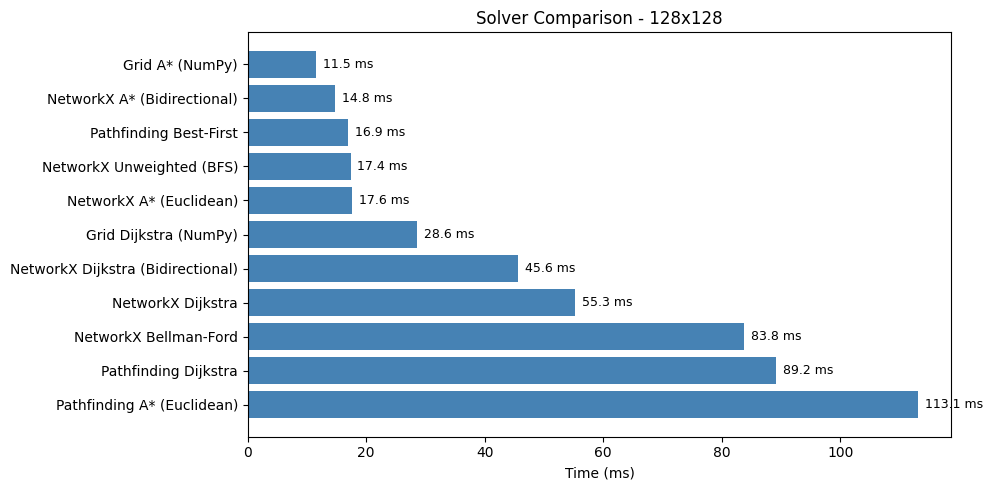

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(df["Solver"], df["Time (ms)"], color="steelblue")
ax.set_xlabel("Time (ms)")
ax.set_title(f"Solver Comparison - {RESOLUTION}x{RESOLUTION}")
ax.invert_yaxis()

for bar, t in zip(bars, df["Time (ms)"]):
    ax.text(
        bar.get_width() + max(df["Time (ms)"]) * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{t:.1f} ms",
        va="center",
        fontsize=9,
    )

plt.tight_layout()
plt.show()

## Path Visualization (All Solvers)

Overlay all solver paths on the elevation map.

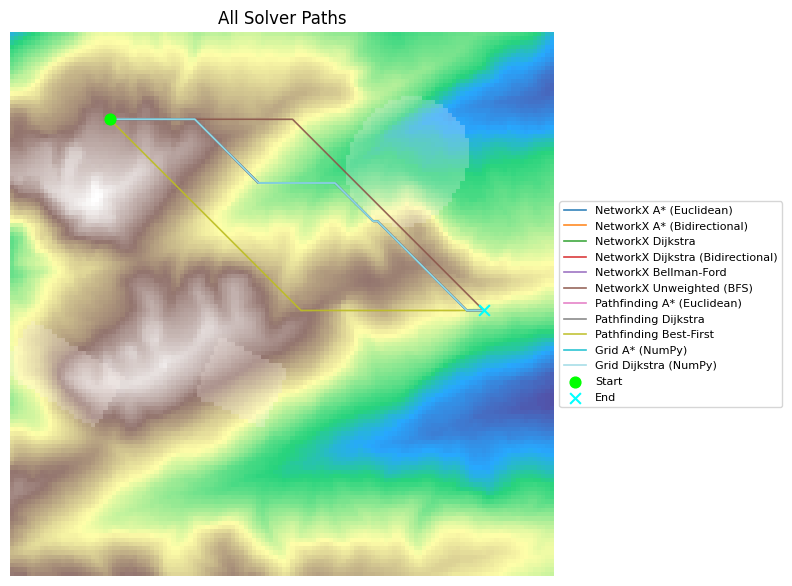

In [10]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(elevation_norm, cmap="terrain", alpha=0.85)
if USE_OBSTACLES:
    ax.imshow(np.ma.masked_where(obstacles_mask == 0, obstacles_mask), cmap="Reds", alpha=0.25)

colors = plt.cm.tab20(np.linspace(0, 1, len(results)))

for color, result in zip(colors, results):
    path = result["path"]
    if len(path) == 0:
        continue
    path_arr = np.array(path)
    ax.plot(path_arr[:, 1], path_arr[:, 0], color=color, linewidth=1.2, alpha=0.9, label=result["solver"])

ax.scatter([start[1]], [start[0]], c="lime", s=60, marker="o", label="Start", zorder=5)
ax.scatter([end[1]], [end[0]], c="cyan", s=60, marker="x", label="End", zorder=5)

ax.set_title("All Solver Paths")
ax.axis("off")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
plt.tight_layout()
plt.show()

## Path Visualization (Per Solver)

Show one subplot per solver to compare route shapes.

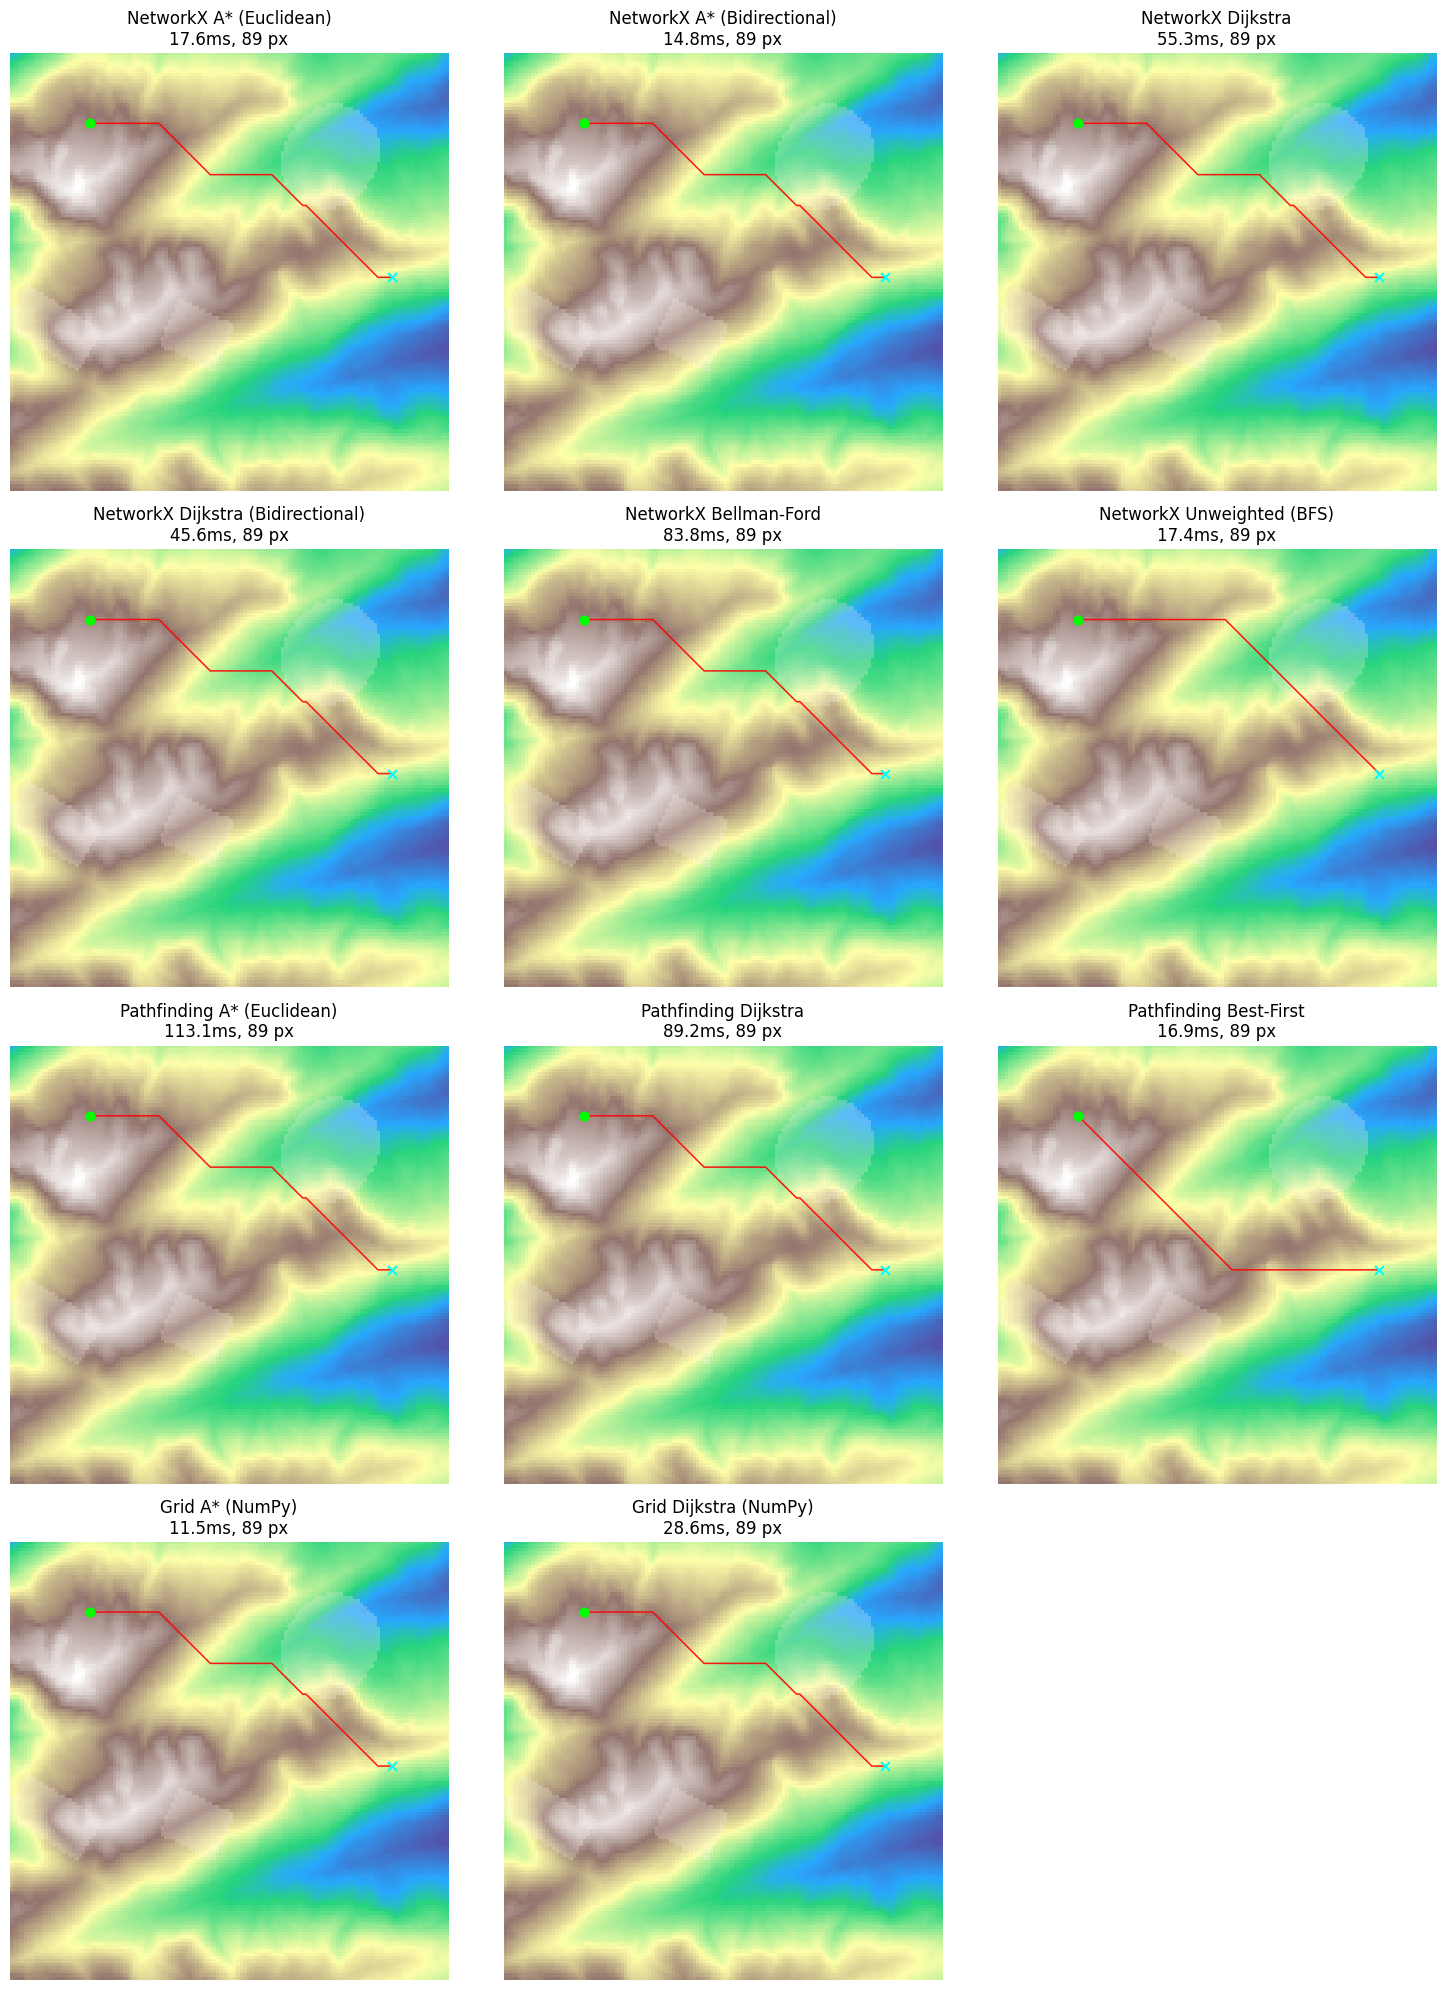

In [11]:
n_solvers = len(results)
cols = min(3, n_solvers)
rows = (n_solvers + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 5 * rows))
if n_solvers == 1:
    axes = np.array([axes])
axes = axes.flatten()

for ax, result in zip(axes, results):
    ax.imshow(elevation_norm, cmap="terrain", alpha=0.85)
    if USE_OBSTACLES:
        ax.imshow(np.ma.masked_where(obstacles_mask == 0, obstacles_mask), cmap="Reds", alpha=0.25)
    path = result["path"]
    if len(path) > 0:
        path_arr = np.array(path)
        ax.plot(path_arr[:, 1], path_arr[:, 0], "r-", linewidth=1.1, alpha=0.9)
    ax.scatter([start[1]], [start[0]], c="lime", s=40, marker="o", zorder=5)
    ax.scatter([end[1]], [end[0]], c="cyan", s=40, marker="x", zorder=5)
    ax.set_title(f"{result['solver']}\n{result['time_ms']:.1f}ms, {result['path_length']} px")
    ax.axis("off")

for ax in axes[n_solvers:]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()